# 01 – Data Understanding: Explorative Datenanalyse (EDA)

**Projekt:** Intelligent EMS – Treiber und 24h-Prognose des Schweizer Day-Ahead-Strompreises.

Dieses Notebook untersucht die beiden Datenquellen aus dem README (Abschnitt *Data Sources*):

| # | Quelle | Inhalt | Auflösung |
|---|---|---|---|
| 1 | [Energy-Charts – Stromproduktion Schweiz (Pronovo)](https://www.energy-charts.info/charts/power/chart.htm?l=de&c=CH&source=pronovo&interval=year) | Nettoerzeugung je Energieträger, Pumpspeicher-Verbrauch, Last, grenzüberschreitender Handel (MW) | 15 min, ab 2020 |
| 2 | [Energy-Charts – Börsenstrompreise und Handelsvolumen Schweiz](https://www.energy-charts.info/charts/price_volume/chart.htm?l=de&c=CH&interval=year) | Day-Ahead-Auktion CH: Preis (EUR/MWh) und Volumen (MWh) | 60 min, ab 2015 |

Beide stammen vom Fraunhofer ISE (Lizenz CC BY 4.0). Das Notebook lädt genau die JSON-Dateien, die die
beiden Charts in der Jahresansicht anzeigen, und speichert sie unter `data/raw/energy_charts_web/`
(nicht im Git). Grafiken landen in `figures/eda/`.

**Ausgangslage: Wir arbeiten mit Day-Ahead-Preisen**

Der CH-Preis jeder Stunde von Tag D wird bereits **am Vortag D−1 um 12:00** in der Day-Ahead-Auktion festgelegt
und ab ca. 12:45 veröffentlicht. Daraus folgt:

- Die Preise der nächsten 12–36 h sind jederzeit **für alle öffentlich bekannt**. Ein EMS kann damit schon heute
  ohne Prognose optimieren. Unser Mehrwert liegt nur jenseits davon: z. B. ein **48h-Profil** aus 24 h festgelegten
  und 24 h prognostizierten Preisen (Tag D+1 bzw. D+2). Das Optimierungspotenzial der Prognose ist entsprechend
  kleiner als das der bekannten Preise.
- Die Muster in diesem Notebook sind **keine gleichzeitigen physikalischen Zusammenhänge**. Die Gebote der Auktion
  beruhen auf Prognosen für den Folgetag (Sonne, Wind, Last). Wenn der Preis bei viel Solarstrom tief ist, heisst
  das: Der Markt hat am Vortag viel Sonne erwartet und deshalb tiefe Preise festgelegt. Die Pronovo-Werte sind
  dagegen **gemessene** Produktion. Wir betreiben also ein **Reverse-Engineering der Preisbildung** der Auktion.

**Leitfragen**
1. *Datenqualität:* Abdeckung, Auflösung, fehlende Werte, Ausreisser, Zeitzonen/Zeitumstellung.
2. *Preis:* Wie verteilt sich der CH-Preis über Jahre, Tageszeiten und Saisons? Wie volatil ist er?
3. *Erzeugung:* Wie setzt sich die Schweizer Produktion zusammen und wie verändert sie sich (Solar-Ausbau, Winterlücke)?
4. *Zusammenhang:* Welche Erzeugungs- und Lastgrössen preist die Auktion offenbar ein – und reichen die Daten für eine Prognose über die bekannten 24 h hinaus (Ziel nMAE < 10 %)?

## 0 Setup

In [1]:
from __future__ import annotations

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from cycler import cycler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "energy_charts_web"
FIG = ROOT / "figures" / "eda"
RAW.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

TZ = "Europe/Zurich"
NOW = pd.Timestamp.now(tz=TZ)
PRICE_YEARS = range(2015, NOW.year + 1)    # Day-Ahead CH ab 2015 (wie analysis/06_zielwert.py)
POWER_YEARS = range(2020, NOW.year + 1)    # Pronovo-Daten gibt es auf Energy-Charts ab 2020

# Einheitlicher Grafikstil wie in analysis/common.py
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=COLORS),
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 1.5, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})
pd.set_option("display.float_format", "{:,.2f}".format)


def save(fig, name: str) -> None:
    fig.savefig(FIG / name)

## 1 Daten laden

Die Charts laden je Jahr eine JSON-Datei im Highcharts-Format: eine Liste von Reihen mit `name`, `data` und
(in der ersten Reihe) den Zeitstempeln `xAxisValues` in Unix-Millisekunden (UTC).

- Erzeugung: `charts/power/data/ch/year_pronovo_<Jahr>.json`
- Preis/Volumen: `charts/price_volume/data/ch/year_dayahead_<Jahr>.json`

Abgeschlossene Jahre werden aus dem Cache gelesen, das laufende Jahr wird immer neu geladen.

In [2]:
BASE = "https://www.energy-charts.info/charts"


def fetch_year(kind: str, path: str, year: int) -> list[dict] | None:
    cache = RAW / kind / f"{year}.json"
    if cache.exists() and year < NOW.year:
        return json.loads(cache.read_text(encoding="utf-8"))
    r = requests.get(f"{BASE}/{path}".format(year=year), timeout=120)
    time.sleep(1)  # Server schonen
    if r.status_code != 200:
        return None
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(r.text, encoding="utf-8")
    return r.json()


def to_frame(series: list[dict]) -> pd.DataFrame:
    index = pd.to_datetime(series[0]["xAxisValues"], unit="ms", utc=True)
    cols = {s["name"]["de"] if isinstance(s["name"], dict) else s["name"][0]["de"]: s["data"] for s in series}
    return pd.DataFrame(cols, index=index).apply(pd.to_numeric, errors="coerce")


def load(kind: str, path: str, years) -> tuple[pd.DataFrame, dict]:
    parts, meta = [], {}
    for y in years:
        series = fetch_year(kind, path, y)
        if series is None:
            print(f"{kind} {y}: nicht verfügbar")
            continue
        parts.append(to_frame(series))
        meta = {k: v for k, v in series[0].items() if k not in ("data", "xAxisValues")}
    df = pd.concat(parts).sort_index()
    df = df[~df.index.duplicated(keep="last")]
    df.index.name = "time_utc"
    return df, meta


power, power_meta = load("power_pronovo", "power/data/ch/year_pronovo_{year}.json", POWER_YEARS)
price, price_meta = load("price_dayahead", "price_volume/data/ch/year_dayahead_{year}.json", PRICE_YEARS)
print("Reihen in der Preisdatei:", list(price.columns))
# 2015–2017 enthält die Datei zusätzlich die Auktion IT-North-CH; für das Projekt zählt nur die CH-Auktion.
price = price[["Day Ahead Auktion (CH)", "Day Ahead Auktion (CH), Volumen"]].set_axis(["price", "volume"], axis=1)

print("Erzeugung:", power.shape, power.index.min(), "→", power.index.max())
print("  Datenquelle:", power_meta.get("datasource"), "|", power_meta.get("comment", [{}])[0].get("de"))
print("Preis/Volumen:", price.shape, price.index.min(), "→", price.index.max())
print("  Datenquelle:", price_meta.get("datasource"))

Reihen in der Preisdatei: ['Day Ahead Auktion (CH)', 'Day Ahead Auktion (IT-North-CH)', 'Day Ahead Auktion (CH), Volumen']
Erzeugung: (233756, 27) 2019-12-31 23:00:00+00:00 → 2026-08-31 21:45:00+00:00
  Datenquelle: Pronovo, ENTSO-E, BFE | Diese Daten werden mit einem Zeitversatz von einem Monat  veröffentlicht.
Preis/Volumen: (103800, 2) 2014-12-31 23:00:00+00:00 → 2026-11-03 22:00:00+00:00
  Datenquelle: ENTSO-E, EPEX SPOT


## 2 Datenqualität

### 2.1 Struktur, Datentypen und Kennzahlen

In [3]:
print("Spalten Erzeugung (MW):")
print(power.dtypes.to_string())
power.describe().T

Spalten Erzeugung (MW):
Grenzüberschreitender Stromhandel         float64
Wasser                                    float64
Biogas                                    float64
Biomasse                                  float64
Klärgas                                   float64
Energiepflanzen                           float64
Forst- und Landwirtschaftliche Abfälle    float64
Kehrichtverbrennung                       float64
Wind                                      float64
Photovoltaik                              float64
Last                                      float64
Abwasser                                  float64
Ausleitwasser                             float64
Dotierwasser                              float64
Durchlaufwasser                           float64
Pumpspeicher Erzeugung                    float64
Speicherwasser                            float64
Trinkwasser                               float64
Pumpspeicher Verbrauch                    float64
Kernenergie               

,count,mean,std,min,25%,50%,75%,max
Grenzüberschreitender Stromhandel,"233,750.00",-255.07,"2,368.92","-8,812.90","-1,751.50",62.40,"1,462.20","6,129.10"
Wasser,"35,136.00","4,105.69","1,933.07",988.70,"2,523.78","3,651.90","5,456.80","9,545.90"
Biogas,"222,144.00",33.97,4.29,20.60,30.60,34.30,37.00,47.70
Biomasse,"11,612.00",171.41,8.88,144.40,165.07,172.00,177.60,196.10
Klärgas,"222,144.00",11.49,1.57,5.90,10.50,11.50,12.50,19.20
Energiepflanzen,"93,604.00",3.54,2.17,0.20,1.00,4.00,5.60,7.30
Forst- und Landwirtschaftliche Abfälle,"67,200.00",45.12,13.39,15.60,33.80,46.10,54.00,76.10
Kehrichtverbrennung,"222,144.00",158.33,42.15,63.00,117.00,167.50,189.80,"1,519.00"
Wind,"233,756.00",17.53,15.63,0.00,5.40,12.00,25.90,84.80
Photovoltaik,"233,756.00",621.41,"1,102.15",0.00,0.00,10.10,833.30,"6,640.50"


In [4]:
price.describe().T

,count,mean,std,min,25%,50%,75%,max
price,"103,800.00",88.22,85.54,-463.68,37.76,58.14,109.87,871.61
volume,"103,788.00","2,880.34",783.05,952.90,"2,358.80","2,735.00","3,211.80","7,835.90"


### 2.2 Zeitliche Auflösung und Abdeckung

Die Auflösung wird aus dem Abstand zwischen zwei Zeitstempeln bestimmt. Seit 01.10.2025 handelt die gekoppelte
EU-Day-Ahead-Auktion 15-min-Produkte; geprüft wird, ob die CH-Reihe auf Energy-Charts das abbildet.

In [5]:
def resolution_table(df: pd.DataFrame) -> pd.DataFrame:
    step = df.index.to_series().diff().dt.total_seconds().div(60)
    year = df.index.tz_convert(TZ).year  # Jahre in Lokalzeit (wie im Chart)
    t = pd.DataFrame({"Auflösung [min]": step, "Jahr": year})
    out = t.groupby("Jahr")["Auflösung [min]"].agg(lambda s: s.value_counts().to_dict()).to_frame()
    out["Werte"] = t.groupby("Jahr").size()
    out["von (Lokalzeit)"] = df.index.tz_convert(TZ).to_series().groupby(year).min()
    out["bis (Lokalzeit)"] = df.index.tz_convert(TZ).to_series().groupby(year).max()
    return out


print("Preis:")
display(resolution_table(price))
print("Erzeugung:")
display(resolution_table(power))

Preis:


,Auflösung [min],Werte,von (Lokalzeit),bis (Lokalzeit)
Jahr,,,,
2015,{60.0: 8759},8760,2015-01-01 00:00:00+01:00,2015-12-31 23:00:00+01:00
2016,{60.0: 8784},8784,2016-01-01 00:00:00+01:00,2016-12-31 23:00:00+01:00
2017,{60.0: 8760},8760,2017-01-01 00:00:00+01:00,2017-12-31 23:00:00+01:00
2018,{60.0: 8760},8760,2018-01-01 00:00:00+01:00,2018-12-31 23:00:00+01:00
2019,{60.0: 8760},8760,2019-01-01 00:00:00+01:00,2019-12-31 23:00:00+01:00
2020,{60.0: 8784},8784,2020-01-01 00:00:00+01:00,2020-12-31 23:00:00+01:00
2021,{60.0: 8760},8760,2021-01-01 00:00:00+01:00,2021-12-31 23:00:00+01:00
2022,{60.0: 8760},8760,2022-01-01 00:00:00+01:00,2022-12-31 23:00:00+01:00
2023,{60.0: 8760},8760,2023-01-01 00:00:00+01:00,2023-12-31 23:00:00+01:00


Erzeugung:


,Auflösung [min],Werte,von (Lokalzeit),bis (Lokalzeit)
Jahr,,,,
2020,{15.0: 35135},35136,2020-01-01 00:00:00+01:00,2020-12-31 23:45:00+01:00
2021,{15.0: 35040},35040,2021-01-01 00:00:00+01:00,2021-12-31 23:45:00+01:00
2022,{15.0: 35040},35040,2022-01-01 00:00:00+01:00,2022-12-31 23:45:00+01:00
2023,{15.0: 35040},35040,2023-01-01 00:00:00+01:00,2023-12-31 23:45:00+01:00
2024,{15.0: 35136},35136,2024-01-01 00:00:00+01:00,2024-12-31 23:45:00+01:00
2025,{15.0: 35040},35040,2025-01-01 00:00:00+01:00,2025-12-31 23:45:00+01:00
2026,{15.0: 23324},23324,2026-01-01 00:00:00+01:00,2026-08-31 23:45:00+02:00


### 2.3 Fehlende Werte und Lücken

Neben `NaN` prüfen wir, ob im regelmässigen Raster Zeitstempel ganz fehlen (z. B. durch die Zeitumstellung).
Alle Zeitstempel sind in UTC und damit lückenlos; Jahre werden in Lokalzeit (Europe/Zurich) gezählt.

In [6]:
def missing_report(df: pd.DataFrame, freq: str) -> pd.DataFrame:
    full = pd.date_range(df.index.min(), df.index.max(), freq=freq, tz="UTC")
    missing_ts = full.difference(df.index)
    print(f"Zeitstempel im {freq}-Raster: {len(full):,}, vorhanden: {len(df):,}, fehlend: {len(missing_ts):,}")
    if len(missing_ts):
        print("  erste fehlende:", list(missing_ts[:5]))
    na = df.isna().groupby(df.index.tz_convert(TZ).year).sum()
    return na.loc[:, na.sum() > 0] if (na.sum() > 0).any() else pd.DataFrame({"NaN": ["keine"]})


print("Preis:")
display(missing_report(price, "1h"))
print("Erzeugung (NaN durch Schema-Änderungen 2020/2021 siehe 2.4):")
display(missing_report(power, "15min"))

Preis:
Zeitstempel im 1h-Raster: 103,800, vorhanden: 103,800, fehlend: 0


,volume
time_utc,
2015,1
2016,1
2017,1
2018,1
2019,1
2020,1
2021,1
2022,1
2023,1


Erzeugung (NaN durch Schema-Änderungen 2020/2021 siehe 2.4):
Zeitstempel im 15min-Raster: 233,756, vorhanden: 233,756, fehlend: 0


,Grenzüberschreitender Stromhandel,Wasser,Biogas,Biomasse,Klärgas,Energiepflanzen,Forst- und Landwirtschaftliche Abfälle,Kehrichtverbrennung,Abwasser,Ausleitwasser,...,Trinkwasser,Pumpspeicher Verbrauch,Kernenergie,Erdgas Dampfturbine,Gas- und Dampfkombikraftwerk,Gasturbine,Verbrennungsmotor,Holzenergie,Gasförmige fossile Energieträger,Flüssige fossile Energieträger
time_utc,,,,,,,,,,,,,,,,,,,,,
2020,0,0,11612,23524,11612,11612,11612,11612,35136,35136,...,35136,35136,35136,35136,35136,35136,35136,35136,35136,35136
2021,0,35040,0,35040,0,0,0,0,0,0,...,0,35040,35040,35040,35040,35040,35040,35040,35040,35040
2022,0,35040,0,35040,0,0,35040,0,0,0,...,0,26204,26204,26204,26204,26204,26204,35040,35040,35040
2023,0,35040,0,35040,0,35040,26404,0,0,0,...,0,0,0,26404,26404,26404,26404,8636,8636,8636
2024,0,35136,0,35136,0,35136,35136,0,0,0,...,0,0,0,35136,35136,35136,35136,0,0,0
2025,3,35040,0,35040,0,35040,35040,0,0,0,...,0,0,0,35040,35040,35040,35040,0,0,0
2026,3,23324,0,23324,0,23324,23324,0,0,0,...,0,0,0,23324,23324,23324,23324,0,0,0


### 2.4 Schema-Änderungen in den Pronovo-Daten

Die Pronovo-Reihen sind nicht in allen Jahren gleich aufgeschlüsselt. Die Tabelle zeigt je Reihe den Anteil
vorhandener Werte pro Jahr (leer = Reihe gibt es in diesem Jahr nicht).

In [7]:
coverage = power.notna().groupby(power.index.tz_convert(TZ).year).mean().T
coverage.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

time_utc,2020,2021,2022,2023,2024,2025,2026
Grenzüberschreitender Stromhandel,100%,100%,100%,100%,100%,100%,100%
Wasser,100%,0%,0%,0%,0%,0%,0%
Biogas,67%,100%,100%,100%,100%,100%,100%
Biomasse,33%,0%,0%,0%,0%,0%,0%
Klärgas,67%,100%,100%,100%,100%,100%,100%
Energiepflanzen,67%,100%,100%,0%,0%,0%,0%
Forst- und Landwirtschaftliche Abfälle,67%,100%,0%,25%,0%,0%,0%
Kehrichtverbrennung,67%,100%,100%,100%,100%,100%,100%
Wind,100%,100%,100%,100%,100%,100%,100%
Photovoltaik,100%,100%,100%,100%,100%,100%,100%


**Konsequenz:** 2020 gibt es nur „Wasser“ gesamt; Kernenergie und Pumpspeicher-Verbrauch fehlen bis
30.09.2022; die Kategorien für Biomasse und fossile Kraftwerke werden im Oktober 2022 und im April 2023 umbenannt.
Vollständig ist der Datensatz deshalb erst **ab 01.10.2022** (Jahresvergleiche ab 2023). Davor würde z. B. der
fehlende Kernkraftblock (~20 TWh/Jahr) als scheinbarer Produktionseinbruch erscheinen. Die Gruppierung in
Abschnitt 4 fasst die umbenannten Kategorien zusammen.

### 2.5 Effektive Auflösung der Erzeugungsreihen

Einige Reihen sind zwar im 15-min-Raster abgelegt, ändern sich aber nur einmal pro Stunde (die Stundenwerte
werden viermal wiederholt). Das ist für die Modellierung wichtig: Diese Reihen enthalten keine 15-min-Information.

In [8]:
def changes_per_hour(s: pd.Series) -> float:
    # Anteil der 15-min-Schritte innerhalb einer Stunde, in denen sich der Wert ändert (0 = nur stündlich)
    inner = s.index.minute != 0
    return float((s.diff().ne(0) & inner).sum() / inner.sum())


eff = pd.Series({c: changes_per_hour(power[c].dropna()) for c in power}).sort_values()
eff.to_frame("Anteil Änderungen innerhalb der Stunde").style.format("{:.0%}")

,Anteil Änderungen innerhalb der Stunde
Last,0%
Flüssige fossile Energieträger,13%
Grenzüberschreitender Stromhandel,15%
Gas- und Dampfkombikraftwerk,26%
Abwasser,44%
Dotierwasser,47%
Photovoltaik,51%
Gasturbine,53%
Energiepflanzen,54%
Erdgas Dampfturbine,54%


### 2.6 Ausreisser und Extremwerte im Preis

Negative Preise und Preisspitzen sind keine Messfehler, sondern Marktrealität (Solar-Überschuss bzw.
Knappheit). Sie werden deshalb nicht entfernt, aber gezählt.

In [9]:
# Für Jahresvergleiche: stündliche Preise (15-min-Werte ab 10/2025 zu Stundenmitteln)
price_h = price.resample("1h").agg({"price": "mean", "volume": "sum"}).dropna(subset=["price"])
local = price_h.index.tz_convert(TZ)
price_h["year"], price_h["month"], price_h["hour"] = local.year, local.month, local.hour
price_h["weekend"] = local.day_of_week >= 5
price_h["season"] = price_h["month"].map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Frühling", 4: "Frühling",
                                          5: "Frühling", 6: "Sommer", 7: "Sommer", 8: "Sommer", 9: "Herbst",
                                          10: "Herbst", 11: "Herbst"})

g = price_h.groupby("year")["price"]
q1, q3 = g.quantile(0.25), g.quantile(0.75)
yearly = pd.DataFrame({
    "Mittel": g.mean(), "Median": g.median(), "Std": g.std(), "Min": g.min(), "Max": g.max(),
    "Std. < 0 €": g.apply(lambda s: (s < 0).sum()),
    "Std. > 300 €": g.apply(lambda s: (s > 300).sum()),
    "IQR-Ausreisser": [((s < q1[y] - 3 * (q3[y] - q1[y])) | (s > q3[y] + 3 * (q3[y] - q1[y]))).sum()
                       for y, s in g],
    "Stunden": g.size(),
})
yearly

,Mittel,Median,Std,Min,Max,Std. < 0 €,Std. > 300 €,IQR-Ausreisser,Stunden
year,,,,,,,,,
2015,40.30,40.94,13.15,-11.66,114.98,9,0,1,8760
2016,37.88,34.33,16.78,-45.68,120.90,24,0,11,8784
2017,46.00,41.25,19.60,-49.95,179.92,5,0,43,8760
2018,52.22,51.36,16.43,-30.62,161.35,29,0,12,8760
2019,40.92,39.97,12.33,-39.45,108.11,17,0,19,8760
2020,34.00,34.59,14.75,-59.61,126.70,75,0,39,8784
2021,114.94,79.68,83.94,-79.40,532.21,41,402,26,8760
2022,281.65,251.30,128.20,-1.00,871.61,1,3132,2,8760
2023,107.47,106.47,40.47,-142.88,268.80,76,0,12,8760


## 3 EDA Börsenstrompreis und Handelsvolumen

### 3.1 Zeitverlauf

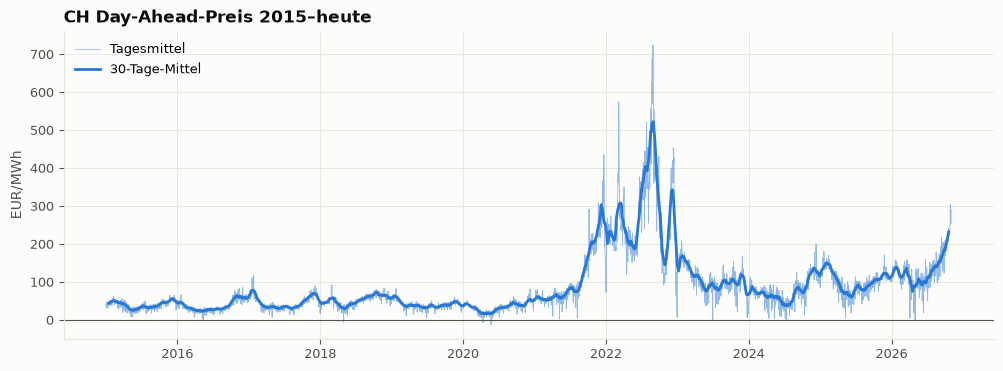

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
daily = price_h["price"].tz_convert(TZ).resample("D").mean()
ax.plot(daily.index, daily, color=COLORS[0], linewidth=0.6, alpha=0.5, label="Tagesmittel")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=COLORS[0], linewidth=2, label="30-Tage-Mittel")
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("CH Day-Ahead-Preis 2015–heute")
ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper left")
save(fig, "01_preis_zeitverlauf.png")

### 3.2 Verteilung

Die Energiekrise 2022 verschiebt die Verteilung massiv. Für die Verteilung je Jahr verwenden wir deshalb
Boxplots ohne Ausreisser-Punkte und ein Histogramm der letzten zwei Jahre.

Schiefe letzte 24 Monate: -0.37, Kurtosis: 5.55


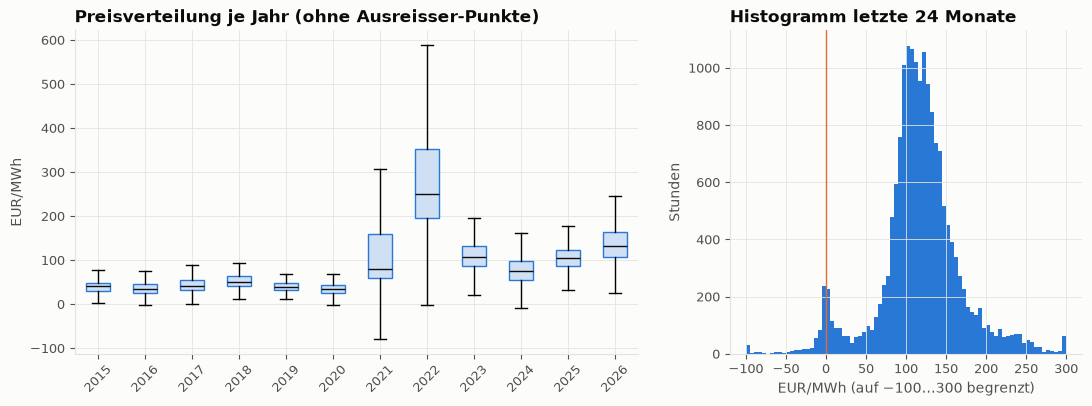

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
years = sorted(price_h["year"].unique())
axes[0].boxplot([price_h.loc[price_h["year"] == y, "price"] for y in years], tick_labels=years, showfliers=False,
                patch_artist=True, boxprops={"facecolor": "#cfe0f5", "edgecolor": COLORS[0]},
                medianprops={"color": INK})
axes[0].set_title("Preisverteilung je Jahr (ohne Ausreisser-Punkte)")
axes[0].set_ylabel("EUR/MWh")
axes[0].tick_params(axis="x", rotation=45)

recent = price_h.loc[price_h.index >= price_h.index.max() - pd.Timedelta(days=730), "price"]
axes[1].hist(recent.clip(-100, 300), bins=80, color=COLORS[0])
axes[1].axvline(0, color=COLORS[1], linewidth=1)
axes[1].set_title("Histogramm letzte 24 Monate")
axes[1].set_xlabel("EUR/MWh (auf −100…300 begrenzt)")
axes[1].set_ylabel("Stunden")
save(fig, "02_preis_verteilung.png")
print(f"Schiefe letzte 24 Monate: {recent.skew():.2f}, Kurtosis: {recent.kurt():.2f}")

### 3.3 Tages- und Saisonmuster

Je Saison und Tagtyp zeigt die Linie den Median (P50) und das Band den Bereich zwischen dem 25. und dem
75. Perzentil, also die mittleren 50 % aller Stunden. Die Profile werden zweimal berechnet: ab 2015 und
ohne die Energiekrise 2022–2023, deren extremes Preisniveau die Bänder sonst stark aufbläht.

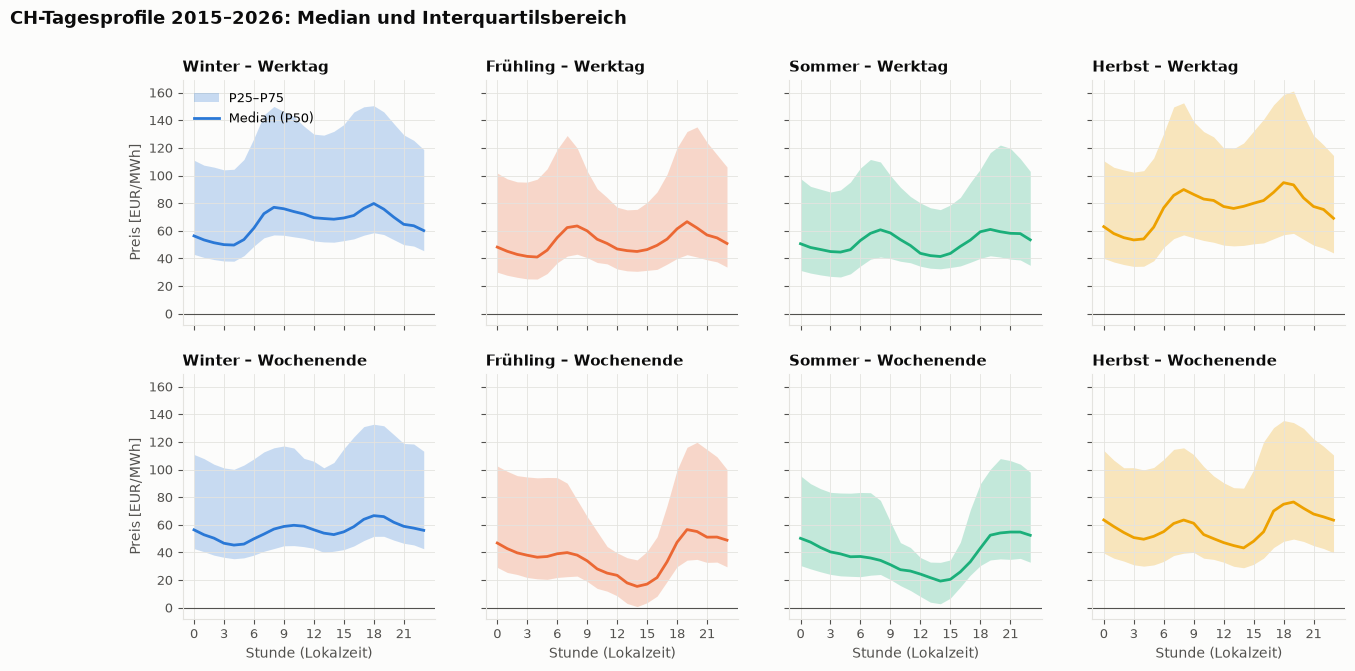

In [12]:
recent_h = price_h[price_h.index >= pd.Timestamp("2024-01-01", tz="UTC")]
SEASON_ORDER = ["Winter", "Frühling", "Sommer", "Herbst"]


def profile_quantiles(df: pd.DataFrame) -> pd.DataFrame:
    # P25/P50/P75 je Tagtyp, Saison und Stunde
    q = df.groupby(["weekend", "season", "hour"])["price"].quantile([0.25, 0.5, 0.75]).unstack()
    q.columns = ["P25", "P50", "P75"]
    return q


def plot_profiles(df: pd.DataFrame, title: str, name: str) -> pd.DataFrame:
    q = profile_quantiles(df)
    fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
    for r, (weekend, day) in enumerate(((False, "Werktag"), (True, "Wochenende"))):
        for c, season in enumerate(SEASON_ORDER):
            ax, p = axes[r, c], q.loc[(weekend, season)]
            ax.fill_between(p.index, p["P25"], p["P75"], color=COLORS[c], alpha=0.25, linewidth=0,
                            label="P25–P75")
            ax.plot(p.index, p["P50"], color=COLORS[c], linewidth=2, label="Median (P50)")
            ax.axhline(0, color=INK_2, linewidth=0.8)
            ax.set_title(f"{season} – {day}", fontsize=11)
            ax.set_xticks(range(0, 24, 3))
            if r == 1:
                ax.set_xlabel("Stunde (Lokalzeit)")
        axes[r, 0].set_ylabel("Preis [EUR/MWh]")
    axes[0, 0].legend(loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    save(fig, name)
    return q


years_all = f"{price_h['year'].min()}–{price_h['year'].max()}"
q_all = plot_profiles(price_h, f"CH-Tagesprofile {years_all}: Median und Interquartilsbereich",
                      "03_tagesprofile_perzentile.png")

,IQR-Breite mit 2022–23,IQR-Breite ohne 2022–23,Median-Tagesspanne ohne 2022–23
season,,,
Winter,75.29,45.64,22.24
Frühling,64.42,39.79,25.66
Sommer,56.73,41.24,21.20
Herbst,76.41,64.43,29.84


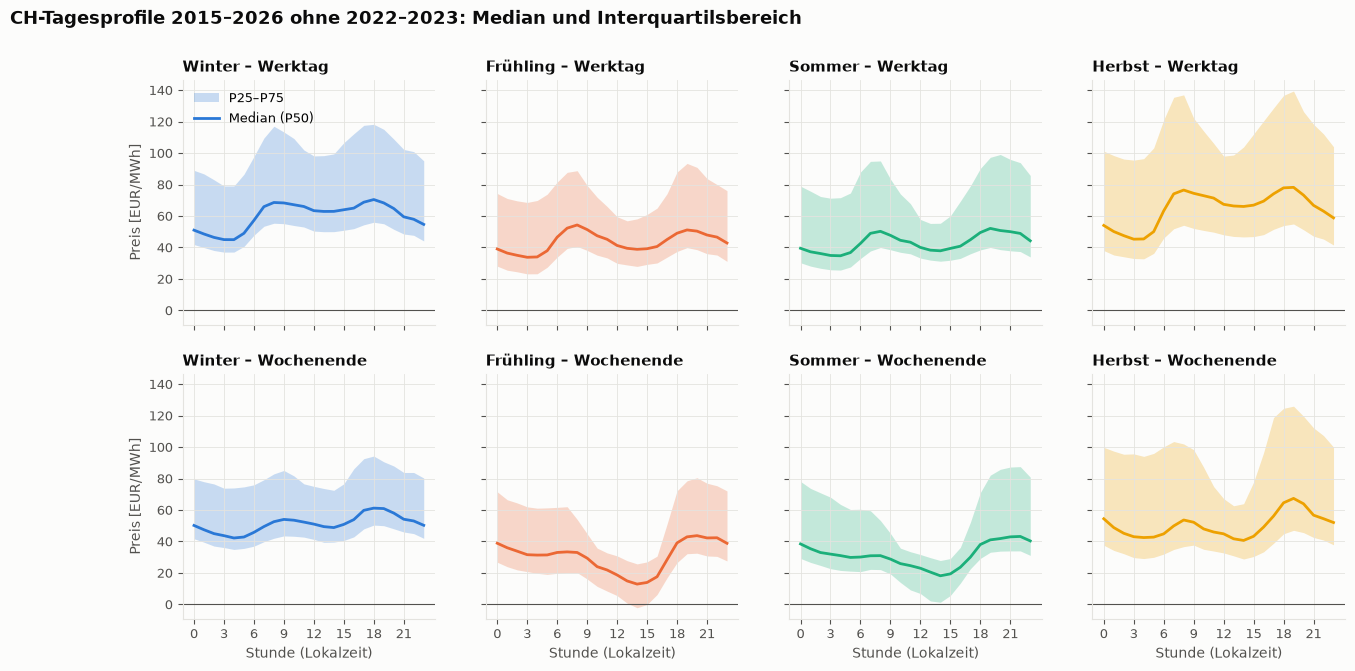

In [13]:
no_crisis = price_h[~price_h["year"].isin([2022, 2023])]
q_nc = plot_profiles(no_crisis, f"CH-Tagesprofile {years_all} ohne 2022–2023: Median und Interquartilsbereich",
                     "03b_tagesprofile_perzentile_ohne_2022_2023.png")

# Vergleich: mittlere Breite des Interquartilsbereichs je Saison
width = pd.DataFrame({
    "IQR-Breite mit 2022–23": (q_all["P75"] - q_all["P25"]).groupby(level="season").mean(),
    "IQR-Breite ohne 2022–23": (q_nc["P75"] - q_nc["P25"]).groupby(level="season").mean(),
    "Median-Tagesspanne ohne 2022–23": q_nc["P50"].groupby(level=["weekend", "season"]).agg(
        lambda s: s.max() - s.min()).groupby(level="season").mean(),
}).loc[SEASON_ORDER]
width

**Beobachtung:** Im Sommer und Frühling gibt es ein klares Tagesprofil, im Winter ist es flacher. Am teuersten
ist der Strom zur Frühstücks- (7–9 Uhr) und Abendessenszeit (18–21 Uhr), am billigsten über Mittag. Das ist eine
Mischung aus Nachfrage (Spitzen morgens/abends) und **erwarteter** Solarproduktion (Mittagstal): Die Auktion legt
die Mittagspreise tief fest, weil sie für den Folgetag viel Sonne erwartet. Am Wochenende ist die Nachfrage
kleiner, das Mittagstal deshalb tiefer.

### 3.4 Volatilität

Für ein Energiemanagement zählt vor allem die **Tagesspanne** (max − min): Sie bestimmt, wie viel man durch
Verschieben von Verbrauch oder Batterieladen sparen kann.

,Ø Spanne,Median,max. Spanne
time_utc,,,
2015,24.03,23.10,70.92
2016,22.12,18.75,76.42
2017,24.09,20.58,101.34
2018,24.62,23.35,102.30
2019,19.81,18.74,70.48
2020,21.57,18.56,86.46
2021,56.72,38.68,214.18
2022,126.42,110.28,368.00
2023,62.42,54.16,235.30


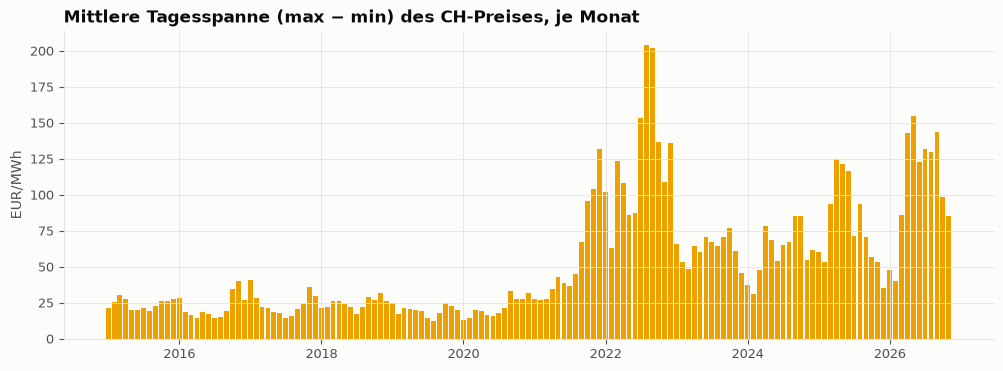

In [14]:
spread = price_h["price"].tz_convert(TZ).resample("D").agg(lambda s: s.max() - s.min())
fig, ax = plt.subplots(figsize=(12, 4))
monthly_spread = spread.resample("MS").mean()
ax.bar(monthly_spread.index, monthly_spread, width=25, color=COLORS[3])
ax.set_title("Mittlere Tagesspanne (max − min) des CH-Preises, je Monat")
ax.set_ylabel("EUR/MWh")
save(fig, "05_tagesspanne.png")
spread.groupby(spread.index.year).agg(["mean", "median", "max"]).rename(
    columns={"mean": "Ø Spanne", "median": "Median", "max": "max. Spanne"})

## 4 EDA Stromproduktion Schweiz (Pronovo)

### 4.1 Gruppierung der Energieträger

Pronovo unterscheidet die Wasserkraft sehr fein. Für die Analyse fassen wir die Reihen zu Gruppen zusammen.
Pumpspeicher-Verbrauch ist negativ, der grenzüberschreitende Handel ist positiv bei Nettoimport.

In [15]:
GROUPS = {
    "Wasser (nur 2020)": ["Wasser"],
    "Laufwasser": ["Durchlaufwasser", "Ausleitwasser", "Dotierwasser", "Trinkwasser", "Abwasser"],
    "Speicherwasser": ["Speicherwasser"],
    "Pumpspeicher": ["Pumpspeicher Erzeugung"],
    "Kernenergie": ["Kernenergie"],
    "Photovoltaik": ["Photovoltaik"],
    "Wind": ["Wind"],
    "Biomasse/Abfall": ["Biogas", "Klärgas", "Holzenergie", "Kehrichtverbrennung", "Biomasse", "Energiepflanzen",
                        "Forst- und Landwirtschaftliche Abfälle"],
    "Fossil": ["Gasförmige fossile Energieträger", "Flüssige fossile Energieträger", "Erdgas Dampfturbine",
               "Gas- und Dampfkombikraftwerk", "Gasturbine", "Verbrennungsmotor"],
}
known = {c for cols in GROUPS.values() for c in cols} | {"Pumpspeicher Verbrauch", "Last",
                                                         "Grenzüberschreitender Stromhandel"}
print("Nicht zugeordnete Spalten:", sorted(set(power.columns) - known) or "keine")

gen_all = pd.DataFrame({g: power[[c for c in cols if c in power]].sum(axis=1, min_count=1)
                        for g, cols in GROUPS.items()})
# Ab hier nur Jahre mit vollständigem Schema (siehe 2.4)
FULL_FROM = pd.Timestamp("2022-10-01", tz=TZ)
power = power[power.index >= FULL_FROM]
gen = gen_all[gen_all.index >= FULL_FROM].drop(columns="Wasser (nur 2020)")
gen_total = gen.sum(axis=1, min_count=1)
step_h = 0.25  # 15-min-Werte in MW → Energie in MWh
gen.head()

Nicht zugeordnete Spalten: keine


,Laufwasser,Speicherwasser,Pumpspeicher,Kernenergie,Photovoltaik,Wind,Biomasse/Abfall,Fossil
time_utc,,,,,,,,
2022-09-30 22:00:00+00:00,"1,786.70",313.70,347.60,"2,944.80",0.00,17.00,222.30,12.30
2022-09-30 22:15:00+00:00,"1,781.90",312.40,355.00,"2,946.00",0.00,16.40,223.80,12.20
2022-09-30 22:30:00+00:00,"1,756.80",296.40,309.40,"2,947.00",0.00,18.70,224.50,12.40
2022-09-30 22:45:00+00:00,"1,722.50",255.80,211.40,"2,947.40",0.00,17.90,222.80,11.70
2022-09-30 23:00:00+00:00,"1,727.70",243.20,297.50,"2,946.90",0.00,24.90,222.70,11.60


### 4.2 Strommix je Jahr (TWh)

Wegen der Schema-Änderungen (2.4) erst ab 2023 (ganze Jahre). Das laufende Jahr ist nur bis zum letzten publizierten Monat vorhanden (Pronovo-Daten erscheinen mit
einem Monat Verzögerung) und deshalb nicht direkt mit den vollen Jahren vergleichbar.

In [16]:
year_loc = power.index.tz_convert(TZ).year
energy_y = ((gen * step_h).groupby(year_loc).sum() / 1e6).loc[2023:]  # TWh
load_y = ((power["Last"] * step_h).groupby(year_loc).sum() / 1e6).loc[2023:]
pump_y = ((power["Pumpspeicher Verbrauch"] * step_h).groupby(year_loc).sum() / 1e6).loc[2023:]

table = energy_y.copy()
table["Summe Erzeugung"] = energy_y.sum(axis=1)
table["Last"] = load_y
table["Pumpspeicher Verbrauch"] = pump_y
table["PV-Anteil %"] = 100 * energy_y["Photovoltaik"] / table["Summe Erzeugung"]
table

,Laufwasser,Speicherwasser,Pumpspeicher,Kernenergie,Photovoltaik,Wind,Biomasse/Abfall,Fossil,Summe Erzeugung,Last,Pumpspeicher Verbrauch,PV-Anteil %
time_utc,,,,,,,,,,,,
2023,15.09,8.96,11.01,23.37,4.91,0.17,2.62,0.22,66.35,61.07,-2.92,7.41
2024,16.86,11.22,11.83,22.30,5.96,0.16,2.56,0.19,71.09,59.63,-2.46,8.39
2025,13.32,8.43,9.65,17.00,7.95,0.16,2.51,0.15,59.16,62.07,-3.39,13.43
2026,7.88,4.92,7.66,12.01,7.77,0.10,1.73,0.11,42.19,42.32,-2.72,18.41


### 4.3 Saisonalität: Winterlücke und Import

Die Schweiz produziert im Sommer mehr als sie verbraucht und importiert im Winter. Diese saisonale
Abhängigkeit vom Ausland ist ein wichtiger Grund, warum der CH-Preis eng an den Nachbarmärkten hängt.

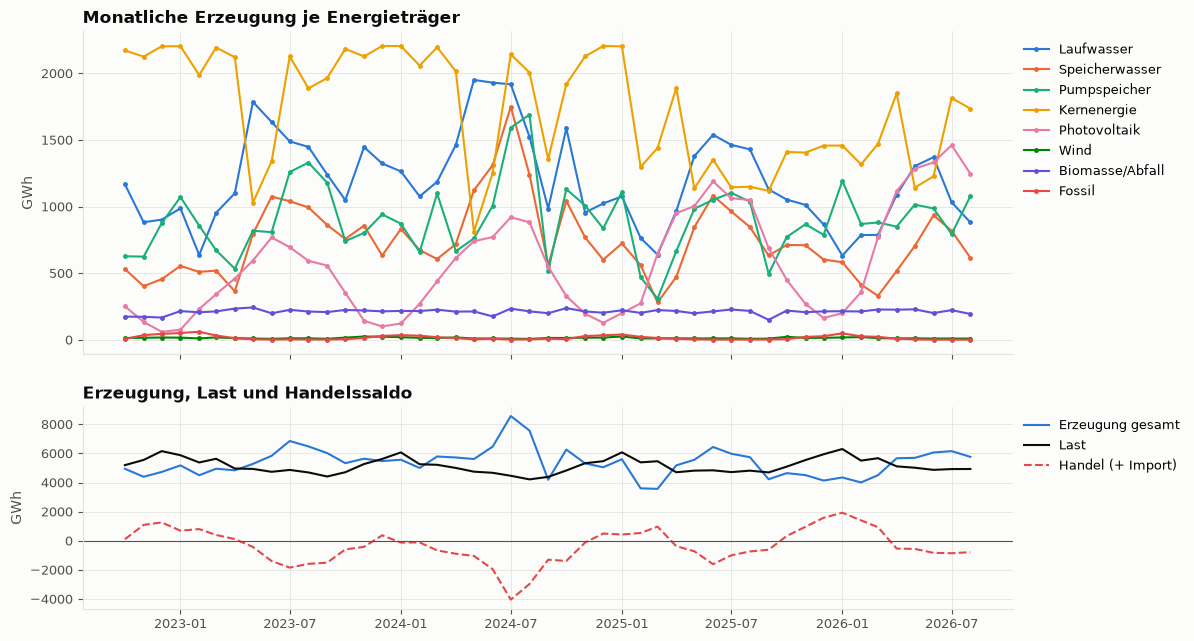

In [17]:
gen_m = (gen * step_h).tz_convert(TZ).resample("MS").sum() / 1e3  # GWh
load_m = (power["Last"] * step_h).tz_convert(TZ).resample("MS").sum() / 1e3
trade_m = (power["Grenzüberschreitender Stromhandel"] * step_h).tz_convert(TZ).resample("MS").sum() / 1e3
# Laufender Monat ist bei Pronovo noch nicht publiziert
last_full = (power.index.max() + pd.Timedelta("15min")).tz_convert(TZ).normalize().replace(day=1)
gen_m, load_m, trade_m = gen_m[gen_m.index < last_full], load_m[load_m.index < last_full], trade_m[trade_m.index < last_full]

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for i, col in enumerate(gen_m.columns):
    axes[0].plot(gen_m.index, gen_m[col], color=COLORS[i % len(COLORS)], label=col, marker="o", markersize=2.5)
axes[0].set_title("Monatliche Erzeugung je Energieträger")
axes[0].set_ylabel("GWh")
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

axes[1].plot(gen_m.index, gen_m.sum(axis=1), color=COLORS[0], label="Erzeugung gesamt")
axes[1].plot(load_m.index, load_m, color=INK, label="Last")
axes[1].plot(trade_m.index, trade_m, color=COLORS[7], linestyle="--", label="Handel (+ Import)")
axes[1].axhline(0, color=INK_2, linewidth=0.8)
axes[1].set_title("Erzeugung, Last und Handelssaldo")
axes[1].set_ylabel("GWh")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "08_strommix_monat.png")

### 4.4 Tagesprofile der Erzeugung (Sommer vs. Winter, letztes volles Jahr)

Linie = Median, Band = 25.–75. Perzentil je Stunde.

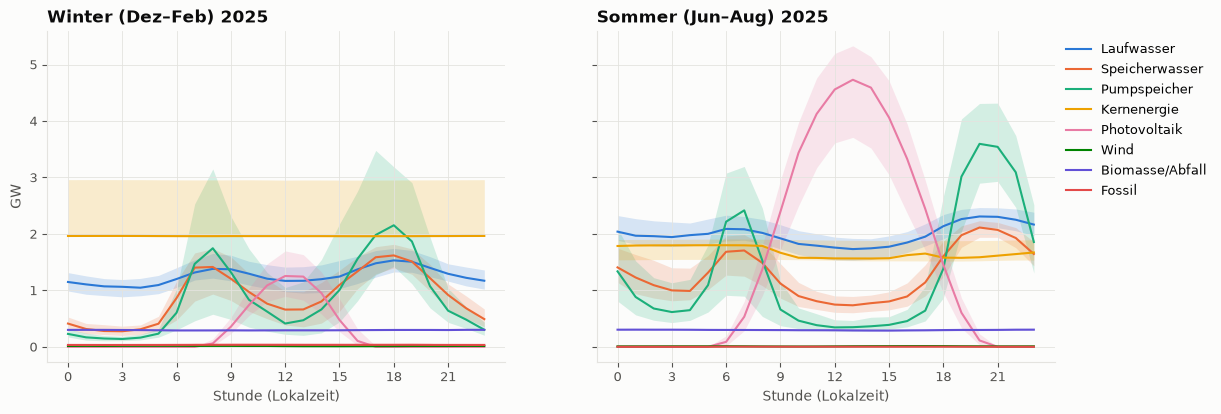

In [18]:
last_year = int(energy_y.index[-2]) if NOW.year in energy_y.index else int(energy_y.index[-1])
sub = gen[gen.index.tz_convert(TZ).year == last_year] / 1e3  # GW
loc = sub.index.tz_convert(TZ)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, months, title in zip(axes, ([12, 1, 2], [6, 7, 8]), ("Winter (Dez–Feb)", "Sommer (Jun–Aug)")):
    m = np.isin(loc.month, months)
    q = sub[m].groupby(loc[m].hour).quantile([0.25, 0.5, 0.75]).unstack()
    for i, col in enumerate(sub.columns):
        c = COLORS[i % len(COLORS)]
        ax.fill_between(q.index, q[(col, 0.25)], q[(col, 0.75)], color=c, alpha=0.18, linewidth=0)
        ax.plot(q.index, q[(col, 0.5)], color=c, label=col)
    ax.set_title(f"{title} {last_year}")
    ax.set_xlabel("Stunde (Lokalzeit)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("GW")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
save(fig, "09_erzeugung_tagesprofil.png")

## 5 Zusammenhang Preis ↔ Erzeugung

Beide Quellen werden auf Stunden (UTC) gebracht und über den Zeitstempel verbunden. Abgeleitete Grössen:

- **Residuallast CH** = Last − Photovoltaik − Wind (was steuerbare Kraftwerke oder Import decken müssen)
- **Handel** = grenzüberschreitender Stromhandel (+ = Nettoimport)
- **Pumpspeicher netto** = Erzeugung + Verbrauch (Verbrauch ist negativ)

**Einordnung:** Der Preis wurde am Vortag aus Prognosen festgelegt, die Pronovo-Werte sind die später gemessene
Produktion. Die Zusammenhänge zeigen also, welche Grössen die Auktion einpreist (Reverse-Engineering), verwässert
durch den Prognosefehler des Marktes. Für unsere Prognose von Tag D+2 stehen diese Grössen nur als Prognosen
(Solar, Wind, Last) zur Verfügung.

In [19]:
hourly = pd.concat([gen.resample("1h").mean(),
                    power[["Last", "Grenzüberschreitender Stromhandel", "Pumpspeicher Verbrauch"]].resample("1h").mean(),
                    price_h[["price", "volume", "hour", "month"]]], axis=1, join="inner").dropna(subset=["price"])
hourly["Residuallast CH"] = hourly["Last"] - hourly["Photovoltaik"] - hourly["Wind"]
hourly["Pumpspeicher netto"] = hourly["Pumpspeicher"] + hourly["Pumpspeicher Verbrauch"]
hourly = hourly.rename(columns={"Grenzüberschreitender Stromhandel": "Handel (+ Import)"})
print(f"Gemeinsamer Zeitraum: {hourly.index.min():%Y-%m-%d} – {hourly.index.max():%Y-%m-%d}, {len(hourly):,} Stunden")

print("Pronovo-Daten ab 01.10.2022 (vollständiges Schema)")
drivers = ["Residuallast CH", "Last", "Photovoltaik", "Wind", "Laufwasser", "Speicherwasser", "Pumpspeicher",
           "Pumpspeicher Verbrauch", "Pumpspeicher netto", "Kernenergie", "Handel (+ Import)", "volume"]
corr = pd.DataFrame({
    "Spearman ρ (ab 10/2022)": [hourly[[d, "price"]].corr(method="spearman").iloc[0, 1] for d in drivers],
    "Spearman ρ (ab 2024)": [hourly.loc["2024":, [d, "price"]].corr(method="spearman").iloc[0, 1] for d in drivers],
}, index=drivers).sort_values("Spearman ρ (ab 2024)", key=np.abs, ascending=False)
corr

Gemeinsamer Zeitraum: 2022-09-30 – 2026-08-31, 34,344 Stunden
Pronovo-Daten ab 01.10.2022 (vollständiges Schema)


,Spearman ρ (ab 10/2022),Spearman ρ (ab 2024)
Residuallast CH,0.57,0.55
Pumpspeicher Verbrauch,0.50,0.53
Pumpspeicher netto,0.43,0.47
Laufwasser,-0.38,-0.37
Pumpspeicher,0.33,0.36
Photovoltaik,-0.27,-0.29
Last,0.33,0.26
volume,0.02,0.10
Speicherwasser,0.05,0.08
Handel (+ Import),0.06,0.06


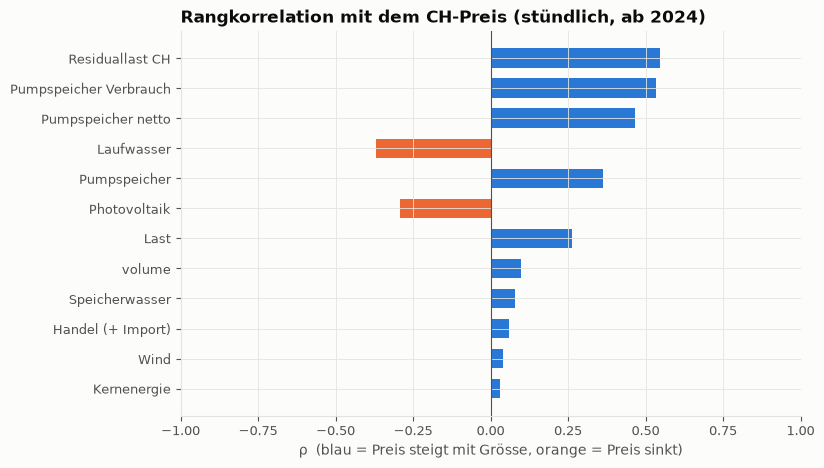

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
t = corr["Spearman ρ (ab 2024)"].iloc[::-1]
ax.barh(t.index, t, color=[COLORS[0] if v >= 0 else COLORS[1] for v in t], height=0.65)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_title("Rangkorrelation mit dem CH-Preis (stündlich, ab 2024)")
ax.set_xlabel("ρ  (blau = Preis steigt mit Grösse, orange = Preis sinkt)")
save(fig, "10_korrelationen.png")

Der Preis wird nicht von einer einzelnen Grösse bestimmt. Viele Reihen (z. B. Pumpspeicher, Speicherwasser)
**reagieren** auf den Preis statt ihn zu treiben: Pumpen bei tiefen, Turbinieren bei hohen Preisen.
Diese Reihen sind für eine Prognose nur als Vergangenheitswerte (Lags) zulässig.

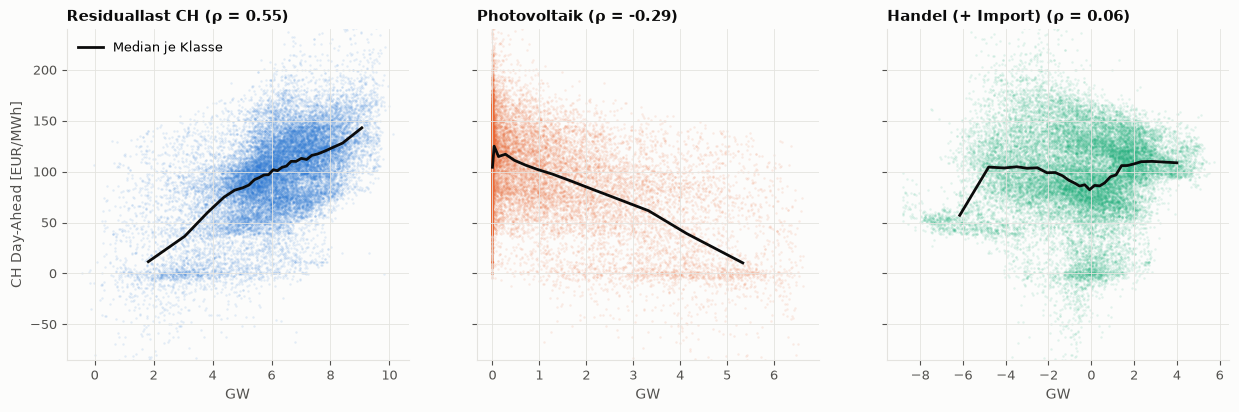

In [21]:
recent_j = hourly.loc["2024":]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, col, color in zip(axes, ["Residuallast CH", "Photovoltaik", "Handel (+ Import)"], COLORS):
    pair = recent_j[[col, "price"]].dropna()
    ax.scatter(pair[col] / 1e3, pair["price"], s=3, alpha=0.12, color=color, linewidths=0)
    bins = pd.qcut(pair[col], 25, duplicates="drop")
    med = pair.groupby(bins, observed=True).median()
    ax.plot(med[col] / 1e3, med["price"], color=INK, linewidth=2, label="Median je Klasse")
    ax.set_title(f"{col} (ρ = {pair.corr(method='spearman').iloc[0, 1]:.2f})", fontsize=11)
    ax.set_xlabel("GW")
axes[0].set_ylabel("CH Day-Ahead [EUR/MWh]")
axes[0].set_ylim(recent_j["price"].quantile(0.002), recent_j["price"].quantile(0.998))
axes[0].legend(loc="upper left")
save(fig, "11_scatter_treiber.png")

### 5.1 Tagesprofil Residuallast vs. Preis

Die Residuallast ist die aussagekräftigste Schweizer Grösse. Legt man ihr Tagesprofil neben das Preisprofil,
sieht man, dass die Form fast deckungsgleich ist (Median und 25.–75. Perzentil, ab 2024).

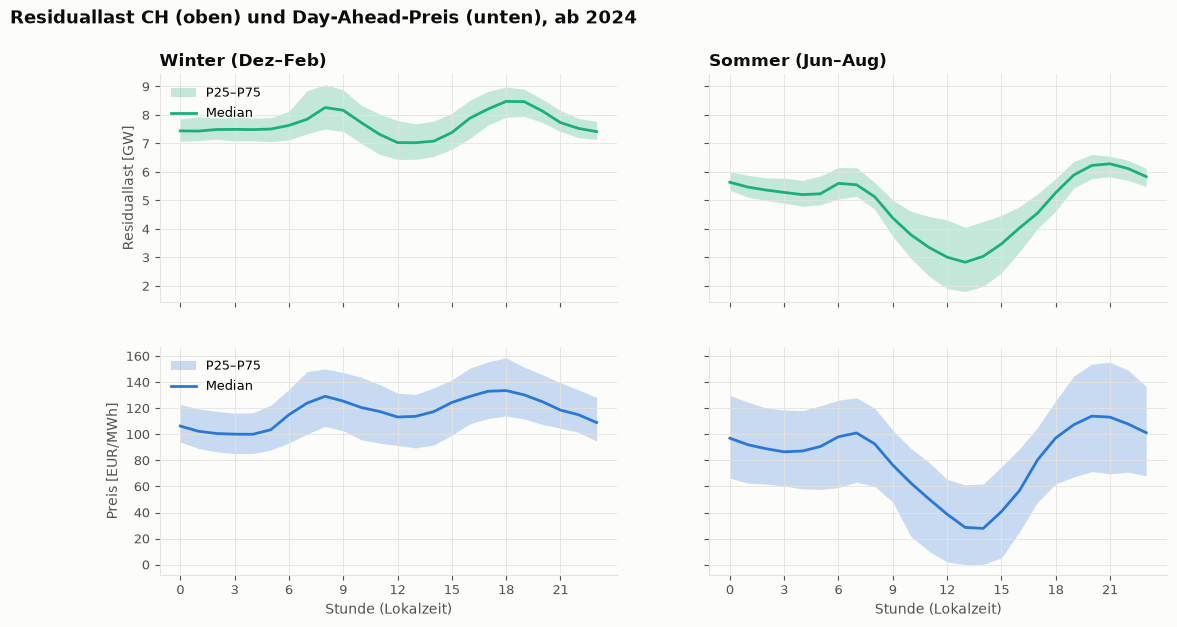

In [22]:
loc_j = recent_j.index.tz_convert(TZ)
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey="row")
for c, (months, title) in enumerate((([12, 1, 2], "Winter (Dez–Feb)"), ([6, 7, 8], "Sommer (Jun–Aug)"))):
    m = np.isin(loc_j.month, months)
    for r, (col, scale, unit, color) in enumerate((("Residuallast CH", 1e3, "Residuallast [GW]", COLORS[2]),
                                                   ("price", 1, "Preis [EUR/MWh]", COLORS[0]))):
        q = (recent_j.loc[m, col] / scale).groupby(loc_j[m].hour).quantile([0.25, 0.5, 0.75]).unstack()
        ax = axes[r, c]
        ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.25, linewidth=0, label="P25–P75")
        ax.plot(q.index, q[0.5], color=color, linewidth=2, label="Median")
        ax.set_xticks(range(0, 24, 3))
        if c == 0:
            ax.set_ylabel(unit)
        if r == 0:
            ax.set_title(title)
        else:
            ax.set_xlabel("Stunde (Lokalzeit)")
for r in range(2):
    axes[r, 0].legend(loc="upper left")
fig.suptitle("Residuallast CH (oben) und Day-Ahead-Preis (unten), ab 2024", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
save(fig, "14_residuallast_preis_tagesprofil.png")

### 5.2 Mittagspreis und Solarproduktion

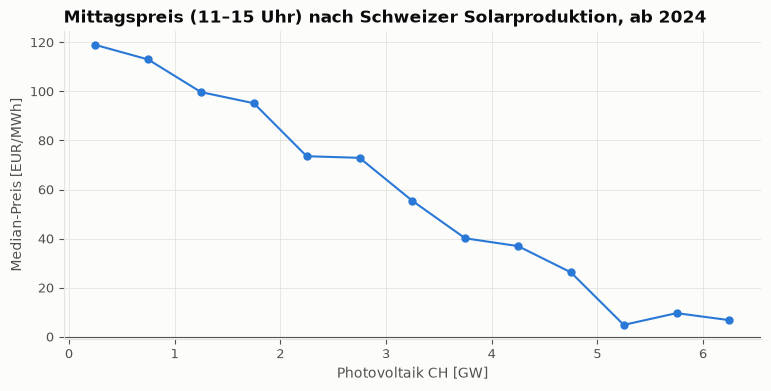

In [23]:
noon = recent_j[recent_j["hour"].between(11, 15)][["Photovoltaik", "price"]].dropna()
bins = pd.cut(noon["Photovoltaik"] / 1e3, np.arange(0, noon["Photovoltaik"].max() / 1e3 + 0.5, 0.5))
g = noon.groupby(bins, observed=True)["price"].agg(["median", "count"])
g = g[g["count"] >= 30]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([b.mid for b in g.index], g["median"], marker="o", markersize=5, color=COLORS[0])
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("Mittagspreis (11–15 Uhr) nach Schweizer Solarproduktion, ab 2024")
ax.set_xlabel("Photovoltaik CH [GW]")
ax.set_ylabel("Median-Preis [EUR/MWh]")
save(fig, "12_solar_mittagspreis.png")

### 5.3 Autokorrelation des Preises

Wie stark hängt der Preis von seinen eigenen Vergangenheitswerten ab? Die Lags 24 h (Vortag) und 168 h
(Vorwoche) sind die Grundlage der naiven Baselines und der Lag-Features im Modell.

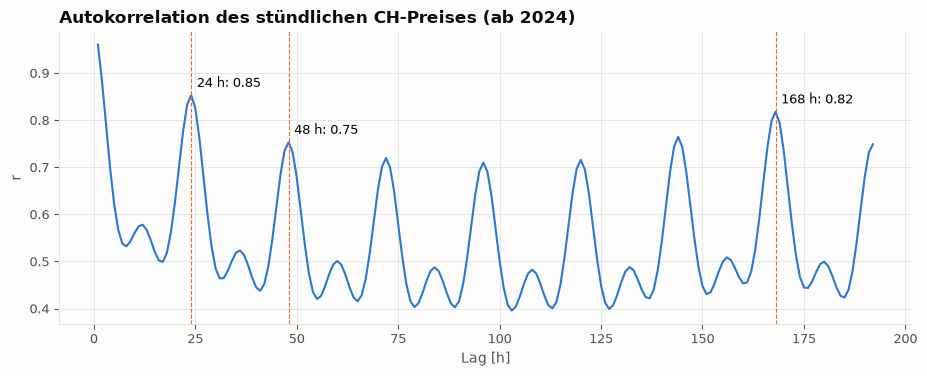

In [24]:
s = price_h.loc["2024":, "price"].asfreq("1h")
lags = range(1, 24 * 8 + 1)
acf = pd.Series([s.autocorr(l) for l in lags], index=lags)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(acf.index, acf, color=COLORS[0])
for l in (24, 48, 168):
    ax.axvline(l, color=COLORS[1], linewidth=0.8, linestyle="--")
    ax.annotate(f"{l} h: {acf[l]:.2f}", (l, acf[l]), textcoords="offset points", xytext=(4, 6), fontsize=9)
ax.set_title("Autokorrelation des stündlichen CH-Preises (ab 2024)")
ax.set_xlabel("Lag [h]")
ax.set_ylabel("r")
save(fig, "13_autokorrelation.png")

### 5.4 Naive Baselines als Referenz für das Ziel nMAE < 10 %

`nMAE = MAE / mittlerer Absolutpreis` (siehe README, Ziel 1). Die naiven Prognosen „gleiche Stunde gestern“
und „gleiche Stunde letzte Woche“ zeigen, wie viel ein Modell herausholen muss. Für das **48h-Profil** ist
„gestern“ nicht verfügbar: Wenn wir nach der Auktion Tag D+2 prognostizieren, ist der jüngste bekannte Preis
der von D+1, also 48 h zurück. Deshalb zusätzlich die Persistenz 48 h.

In [25]:
def nmae(y, yhat):
    pair = pd.concat([y, yhat], axis=1).dropna()
    return 100 * (pair.iloc[:, 0] - pair.iloc[:, 1]).abs().mean() / pair.iloc[:, 0].abs().mean()


s_all = price_h["price"].asfreq("1h")
yr = s_all.index.tz_convert(TZ).year
base = pd.DataFrame({f"nMAE Persistenz {h} h [%]": s_all.groupby(yr).apply(lambda y, h=h: nmae(y, s_all.shift(h).loc[y.index]))
                     for h in (24, 48, 168)})
base

,nMAE Persistenz 24 h [%],nMAE Persistenz 48 h [%],nMAE Persistenz 168 h [%]
time_utc,,,
2015,15.28,21.24,14.07
2016,15.16,21.63,14.37
2017,13.25,19.21,15.10
2018,12.53,17.18,14.80
2019,13.71,18.28,15.08
2020,16.96,23.89,17.75
2021,13.17,18.82,18.30
2022,12.62,18.40,22.61
2023,14.96,20.95,19.05


## 6 Fazit

### Datenqualität (Stand Datenabruf 30.10.2026)

**Börsenstrompreis und Volumen**
- 01.01.2015 – 30.10.2026, 103'704 Stunden, in UTC lückenlos. Keine fehlenden Preise.
- Die CH-Reihe ist auf Energy-Charts auch nach der EU-Umstellung auf 15-min-Produkte (01.10.2025) **stündlich**.
  Eine Prognose für einen 15-min-Tarif (EKZ) gilt deshalb je Stunde.
- Volumen: genau ein fehlender Wert pro Jahr, jeweils 03:00 am Tag der Umstellung auf Sommerzeit (Artefakt der Quelle).
- 2015–2017 enthält die Datei zusätzlich die Auktion *IT-North-CH*; sie wird verworfen.
- Extremwerte sind echte Marktereignisse, keine Fehler: Minimum −464 EUR/MWh (2026), Maximum 872 EUR/MWh (2022).
  Sie werden behalten.

**Stromproduktion (Pronovo)**
- 15-min-Werte 01.01.2020 – 31.08.2026, im Raster lückenlos. Die Daten erscheinen mit **einem Monat Verzögerung**:
  Für eine Live-Prognose sind sie nicht verfügbar, nur für Analyse und Training (bzw. als Lag ≥ 1 Monat).
- Das **Schema wechselt** (2.4): 2020 nur „Wasser“ gesamt, Kernenergie und Pumpspeicher-Verbrauch erst ab
  01.10.2022, Biomasse- und Fossil-Kategorien zweimal umbenannt. Vollständig und vergleichbar erst ab **01.10.2022**.
- Die **Last** liegt nur stündlich vor (jeder Wert viermal wiederholt), der Handelssaldo grösstenteils ebenfalls.
  Wasser-, Kern- und Pumpspeicherwerte sind echte 15-min-Werte.
- Alle Spalten sind numerisch (`float64`); Pumpspeicher-Verbrauch ist negativ, Handel positiv bei Nettoimport.

### Insights

1. **Strukturbrüche im Preisniveau.** Der Jahresmittelpreis lag 2015–2020 bei 34–52 EUR/MWh, stieg in der
   Energiekrise 2022 auf 282 EUR/MWh (3'132 Stunden über 300 EUR/MWh) und liegt 2026 bei 131 EUR/MWh. Ein Modell
   muss mit Niveauwechseln umgehen (z. B. Änderung gegenüber dem Vortag statt Absolutpreis vorhersagen) und darf
   2021–2022 nicht unkritisch fürs Training nutzen.
2. **Die Volatilität nimmt zu – gut für ein EMS.** Negative Preise: 9 Stunden (2015) → ~300 Stunden pro Jahr
   (2024/2025). Die mittlere Tagesspanne stieg von ~22 EUR/MWh (2015–2020) auf 110 EUR/MWh (2026). Je grösser die
   Spanne, desto mehr lässt sich durch Lastverschiebung und Batterie sparen (Ziel 2).
0. **Wir sehen die Preisbildung der Auktion, nicht den Echtzeitmarkt.** Die Preise für die nächsten 24 h sind
   am Vortag festgelegt und öffentlich. Alle folgenden Muster zeigen, wovon die Auktion für den Folgetag ausgeht
   (Reverse-Engineering). Ein EMS kann mit den bekannten Preisen schon optimieren; unser Beitrag ist die
   Verlängerung auf ein 48h-Profil (24 h bekannt + 24 h prognostiziert). Das Zusatzpotenzial ist kleiner.
3. **Ausgeprägtes Tages- und Saisonmuster.** Klares Tagesprofil im Sommer, flacher im Winter. Am teuersten
   zur Frühstücks- und Abendessenszeit, am billigsten über Mittag: eine Mischung aus Nachfrage und erwarteter
   Solarproduktion. Über 2015–2026 zeigen Werktage Spitzen am Morgen und Abend.
   Im Frühling/Sommer am Wochenende fällt der Median um 14 Uhr auf 15–20 EUR/MWh, das 25. Perzentil liegt dort
   nahe 0 (Solar-Überschuss). Ohne die Krisenjahre 2022–2023 bleibt die Form gleich, der Interquartilsbereich
   wird aber deutlich schmaler (Winter Ø 75 → 46 EUR/MWh). Stunde, Wochentag und Saison sind deshalb zentrale
   Features; 2022–2023 sollte man fürs Training höchstens gewichtet verwenden.
4. **Die Schweiz ist im Winter Importland.** Im Sommer exportiert sie bis zu 4 TWh pro Monat, im Winter
   importiert sie bis zu 2 TWh. Der CH-Preis folgt damit stark den Nachbarmärkten.
5. **Schweizer Erzeugung erklärt den Preis nur teilweise.** Stärkster CH-Treiber ist die Residuallast
   (Last − PV − Wind, ρ = 0.55); ihr Tagesprofil hat fast dieselbe Form wie das Preisprofil (5.1).
   Solar ist ein guter Prädiktor (ρ = −0.29, der Mittagspreis fällt mit steigender PV-Produktion deutlich),
   Wind spielt in der Schweiz kaum eine Rolle (ρ = 0.04). Da der Preis am Vortag festgelegt wird, zeigen diese
   Zusammenhänge, welche erwartete Produktion die Auktion einpreist. Pumpspeicher und Speicherwasser **reagieren** auf den Preis (pumpen bei tiefen,
   turbinieren bei hohen Preisen) und sind daher Folge, nicht Ursache. Für das Prognoseziel braucht es zusätzlich
   die europäischen Grössen (Preise und Residuallast DE/FR/IT/AT, Day-Ahead-Prognosen) – das deckt die
   Datenpipeline in `analysis/01_fetch_data.py` ab.
6. **Photovoltaik wächst schnell.** Der PV-Anteil an der Erzeugung stieg von 7 % (2023) auf 13 % (2025) und
   18 % (Jan–Aug 2026). Damit werden Mittagstäler und negative Preise weiter zunehmen.
7. **Starke Autokorrelation, aber naive Prognosen reichen nicht.** Die Lags 24 h und 168 h sind hoch korreliert (r = 0.85 bzw. 0.81, ab 2024).
   Die naive Persistenz erreicht trotzdem je Jahr nur einen nMAE von 13–21 % (24 h) bzw. 14–25 % (168 h).
   Das Ziel nMAE < 10 % verlangt also ein Modell, das den Fehler gegenüber der Persistenz um rund 40 % senkt.
   Für das 48h-Profil (Tag D+2) ist nur der Preis von vor 48 h bekannt; diese Persistenz liegt bei 17–28 %.
   Die Prognose für den zweiten Tag ist damit deutlich schwieriger.

**Eignung der Daten:** Die Preisreihe ist vollständig, lang und sauber und eignet sich als Zielgrösse. Die
Pronovo-Daten eignen sich zur Erklärung der Schweizer Seite (Strommix, Saisonalität, Solar-Effekt), wegen der
Verzögerung von einem Monat aber nicht als Live-Input. Für die 24h-Prognose werden sie deshalb mit
Day-Ahead-Prognosen und Nachbarpreisen ergänzt.